<a href="https://colab.research.google.com/github/adhithya032006/DAV-LAB-/blob/main/Employee_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("employee_salary_dataset.csv")

print("Dataset:")
print(df.head())

print("\nStatistical Summary:")
print(df.describe())


Saving employee_salary_dataset.csv to employee_salary_dataset.csv
Dataset:
   EmployeeID        Name  Department  Experience_Years Education_Level  Age  \
0           1  Employee_1   Marketing                15          Master   53   
1           2  Employee_2  Operations                 7        Bachelor   25   
2           3  Employee_3          IT                12     High School   51   
3           4  Employee_4  Operations                 8             PhD   44   
4           5  Employee_5  Operations                15          Master   36   

   Gender       City  Monthly_Salary  
0  Female      Delhi          111416  
1  Female  Bangalore           95271  
2  Female  Hyderabad           69064  
3    Male      Delhi           95091  
4  Female      Delhi          132450  

Statistical Summary:
       EmployeeID  Experience_Years        Age  Monthly_Salary
count    50.00000         50.000000  50.000000         50.0000
mean     25.50000          9.900000  39.760000      82288.8000

In [ ]:

X_simple = df[["Experience_Years"]]

X_multiple = df[["Experience_Years", "Age"]]

y = df["Monthly_Salary"]


In [ ]:

X_train_s, X_test_s, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

X_train_m, X_test_m, _, _ = train_test_split(
    X_multiple, y, test_size=0.2, random_state=42
)


In [ ]:

simple_model = LinearRegression()

simple_model.fit(X_train_s, y_train)

simple_predictions = simple_model.predict(X_test_s)

print("Simple Linear Regression")

print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])

print("R2 Score:", r2_score(y_test, simple_predictions))

print("RMSE:", np.sqrt(
    mean_squared_error(y_test, simple_predictions)
))


Simple Linear Regression
Intercept: 80302.28954109494
Coefficient: 550.5372028832982
R2 Score: -0.2700756400465425
RMSE: 38697.197519492096


In [ ]:

multiple_model = LinearRegression()

multiple_model.fit(X_train_m, y_train)

multiple_predictions = multiple_model.predict(X_test_m)

print("Multiple Linear Regression")

print("Intercept:", multiple_model.intercept_)
print("Coefficients:", multiple_model.coef_)

print("R2 Score:", r2_score(y_test, multiple_predictions))

print("RMSE:", np.sqrt(
    mean_squared_error(y_test, multiple_predictions)
))


Multiple Linear Regression
Intercept: 82339.6991848979
Coefficients: [563.57949337 -54.03510544]
R2 Score: -0.2822859065179133
RMSE: 38882.76634156728


In [ ]:

new_employee_simple = pd.DataFrame({
    "Experience_Years": [5]
})

new_employee_multiple = pd.DataFrame({
    "Experience_Years": [5],
    "Age": [28]
})

print("Predicted Salary using Simple Regression:",
      simple_model.predict(new_employee_simple)[0])

print("Predicted Salary using Multiple Regression:",
      multiple_model.predict(new_employee_multiple)[0])


Predicted Salary using Simple Regression: 83054.97555551144
Predicted Salary using Multiple Regression: 83644.61369931964


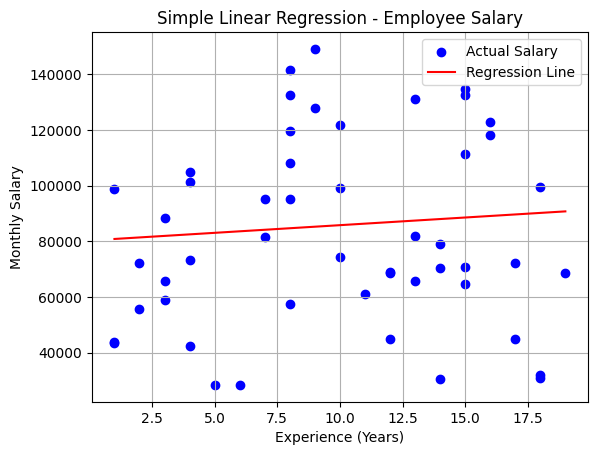

In [ ]:

plt.scatter(
    df["Experience_Years"],
    df["Monthly_Salary"],
    color="blue",
    label="Actual Salary"
)

sorted_df = df.sort_values("Experience_Years")

plt.plot(
    sorted_df["Experience_Years"],
    simple_model.predict(sorted_df[["Experience_Years"]]),
    color="red",
    label="Regression Line"
)

plt.xlabel("Experience (Years)")
plt.ylabel("Monthly Salary")
plt.title("Simple Linear Regression - Employee Salary")
plt.legend()
plt.grid(True)
plt.show()
